## Unsharp Masking

Unsharp masking is an image enhancement method that sharpens edges and fine details by comparing the original image with a blurred version. It can help make crevasses more visible in NISAR satellite images by increasing local contrast.

The method has two main parameters:

- **Radius:** Controls the scale of features being sharpened. A larger radius enhances broader features and transitions.
- **Amount:** Controls the strength of sharpening. A higher amount produces stronger contrast around edges.

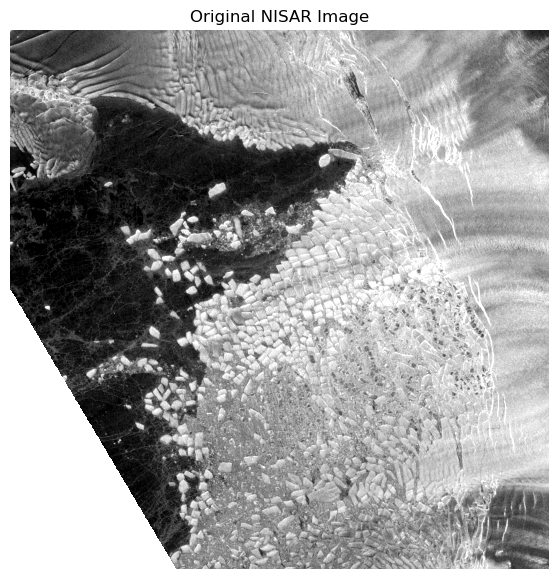

In [4]:

from pathlib import Path
import sys

import h5py
import numpy as np
import matplotlib.pyplot as plt

# Import our unsharp masking function
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

from utils.inference_strategies.unsharp_mask import apply_unsharp_mask

# Locate NISAR data
data_dir = (
    Path.home()
    / "Library/CloudStorage/Box-Box/2026-glaciers/nisar_data/nisar_gcov_pig"
)

# Use the same file as the black top-hat walkthrough
file_path = sorted(data_dir.glob("*.h5"))[0]

# Load a 1000 x 1000 pixel crop
with h5py.File(file_path, "r") as f:
    dataset = f["science/LSAR/GCOV/grids/frequencyB/HHHH"]
    image = dataset[2500:3500, 1000:2000]

# Convert radar backscatter to decibels
valid = np.isfinite(image) & (image > 0)

image_db = np.full(image.shape, np.nan, dtype=np.float32)
image_db[valid] = 10 * np.log10(image[valid])

# Fill invalid pixels temporarily
image_clean = np.where(
    valid,
    image_db,
    np.nanmedian(image_db)
)

# Display original image
vmin, vmax = np.percentile(image_db[valid], [2, 98])

plt.figure(figsize=(7, 7))
plt.imshow(image_db, cmap="gray", vmin=vmin, vmax=vmax)
plt.title("Original NISAR Image")
plt.axis("off")
plt.show()


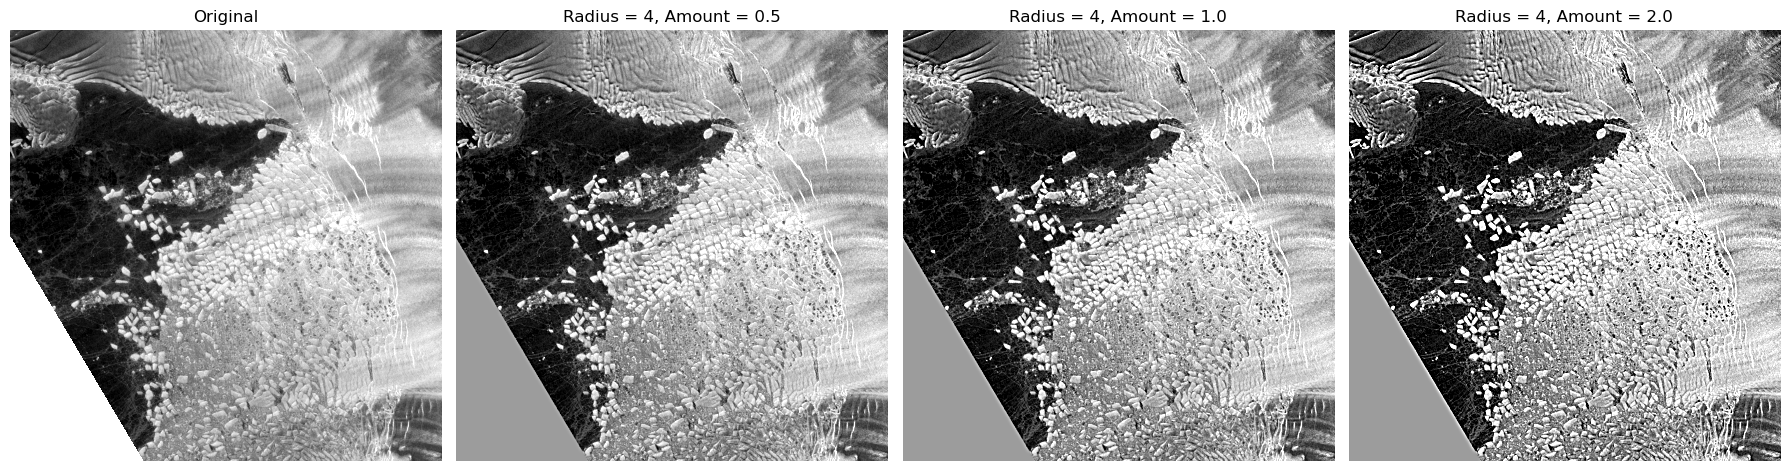

In [5]:

# Test different amount values with radius fixed at 3
radius = 4
amounts = [0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original")
axes[0].axis("off")

for i, amount in enumerate(amounts, start=1):
    enhanced = apply_unsharp_mask(
        image_clean,
        radius=radius,
        amount=amount
    )

    axes[i].imshow(
        enhanced,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    axes[i].set_title(f"Radius = {radius}, Amount = {amount}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


### Comparing Amount Values

Amount values of 0.5, 1.0, and 2.0 are tested while keeping the radius fixed at 4.

**Observations:**

- Amount = 0.5 produces subtle sharpening with limited improvement in feature visibility.
- Amount = 1.0 makes edges and fine details more distinct without significantly changing the overall image.
- Amount = 2.0 creates stronger contrast but also amplifies background texture and noise.

**Preliminary Conclusion:**

Radius = 4 and amount = 1.0 appear to provide a reasonable balance between enhancing potential crevasse features and avoiding excessive sharpening. However, further testing on additional images is needed to evaluate whether this improves crevasse detection.